# 04hycommonthly: monthly currents and a check against the moorings

PF9, step 5. Uses the HYCOM snapshots from 02hycomdownload (and 02a to 02d) in `data/raw/hycom/`.

1. For every snapshot: how much water the model pushes north through the narrowest part of the strait (transport, Sv), its mean temperature, and the near-bottom current and temperature at the position of mooring A3.
2. Monthly means of the currents and temperature, saved as small files in `data/hycom_monthly/` (these, not the raw snapshots, feed the next steps).
3. A check against the measured University of Washington monthly means (`data/uw_monthly.csv` from 03moorings): same month and year where the mooring has data, otherwise the mooring's average for that calendar month (marked).
4. Maps of the monthly mean currents at the surface and near the seabed.

Note: the model transport covers the whole strait, including the Alaskan Coastal Current; the mooring transport excludes it (about 0.1 Sv less). Mooring velocity is a single near-bottom bin in cm/s.

Runs again from the start whenever more years have been downloaded.

## Section 0. Settings

Lines marked `# <-` can be changed.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
HYCOM_DIR = PROJECT_DIR / "data" / "raw" / "hycom"
MONTHLY_DIR = PROJECT_DIR / "data" / "hycom_monthly"
UW_MONTHLY = PROJECT_DIR / "data" / "uw_monthly.csv"
FIG_DIR = PROJECT_DIR / "figures"

STRAIT_LAT_MIN = 65.5  # <- search the narrowest model row of the strait between these latitudes
STRAIT_LAT_MAX = 66.3  # <-
STRAIT_LON_MIN = 189.0  # <- strait longitudes (degrees east; 191 = 169°W)
STRAIT_LON_MAX = 193.5  # <-
A3_LAT = 66.33  # <- mooring A3 position (about 35 km north of the strait)
A3_LON = 191.05  # <- degrees east (168.95°W)
KEEP_DEPTH_M = 60  # <- depth levels kept in the monthly files (the shelf is about 50 m deep)
MAP_YEAR = None  # <- year for the maps; None = the first year found
MAP_STEP = 5  # <- VISUAL: arrow every MAP_STEP cells on the maps

## Section 1. Libraries and helpers

In [2]:
import re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

MONTHLY_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
EARTH_R = 6371000.0
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def open_snapshot(path):
    ds = xr.open_dataset(path, engine="h5netcdf")
    if "time" in ds.dims:
        ds = ds.isel(time=0)
    return ds.load()


def layer_thickness(depths):
    edges = np.r_[0.0, (depths[1:] + depths[:-1]) / 2, depths[-1] + (depths[-1] - depths[-2]) / 2]
    return np.diff(edges)


def bottom_values(da):
    vals = da.values
    valid = ~np.isnan(vals)
    last = valid.shape[0] - 1 - np.argmax(valid[::-1], axis=0)
    out = np.take_along_axis(vals, last[None], axis=0)[0]
    out[~valid.any(axis=0)] = np.nan
    return out

## Section 2. Every snapshot: strait transport and the A3 position

The narrowest model row is found once (the latitude row between `STRAIT_LAT_MIN` and `STRAIT_LAT_MAX` with the fewest water cells between the strait longitudes). Transport = northward current x layer thickness x cell width, summed over the row.

In [3]:
files = sorted(HYCOM_DIR.glob("hycom_*.nc"))
dates = [pd.Timestamp(re.search(r"(\d{8})", f.name).group(1)) for f in files]
print("Snapshots found:", len(files), "from", min(dates).date(), "to", max(dates).date())
print("Years:", sorted({d.year for d in dates}))

first = open_snapshot(files[0])
depths = first["depth"].values
dz = layer_thickness(depths)
rows = first.sel(lat=slice(STRAIT_LAT_MIN, STRAIT_LAT_MAX), lon=slice(STRAIT_LON_MIN, STRAIT_LON_MAX))
wet_counts = (~np.isnan(rows["water_v"].isel(depth=0))).sum("lon")
strait_lat = float(rows["lat"][int(np.argmin(wet_counts.values))])
strait = first.sel(lat=strait_lat).sel(lon=slice(STRAIT_LON_MIN, STRAIT_LON_MAX))
dx = np.deg2rad(float(first["lon"][1] - first["lon"][0])) * EARTH_R * np.cos(np.deg2rad(strait_lat))
wet = ~np.isnan(strait["water_v"].isel(depth=0).values)
print("Strait row:", round(strait_lat, 2), "°N;", int(wet.sum()), "water cells,", round(wet.sum() * dx / 1000), "km of water; cell width", round(dx / 1000, 2), "km")
a3 = first.sel(lat=A3_LAT, lon=A3_LON, method="nearest")
a3_bottom_depth = float(depths[~np.isnan(a3["water_v"].values)].max())
print("A3 model cell:", round(float(a3["lat"]), 2), "°N", round(float(a3["lon"]), 2), "°E; deepest model level there", a3_bottom_depth, "m")

Snapshots found: 490 from 1995-02-01 to 2023-11-29
Years: [1995, 2000, 2005, 2010, 2015, 2019, 2020, 2023]
Strait row: 65.64 °N; 29 water cells, 107 km of water; cell width 3.67 km
A3 model cell: 66.32 °N 191.04 °E; deepest model level there 50.0 m


In [4]:
records = []
for f, d in zip(files, dates):
    ds = open_snapshot(f)
    row = ds.sel(lat=strait_lat).sel(lon=slice(STRAIT_LON_MIN, STRAIT_LON_MAX))
    v = row["water_v"].values
    t = row["water_temp"].values
    transport = float(np.nansum(v * dz[:, None]) * dx / 1e6)
    weights = np.where(np.isnan(v), 0, dz[:, None])
    temp = float(np.nansum(np.nan_to_num(t) * weights) / weights.sum())
    a3c = ds.sel(lat=A3_LAT, lon=A3_LON, method="nearest")
    vv = a3c["water_v"].values
    tt = a3c["water_temp"].values
    ok = ~np.isnan(vv)
    records.append({"date": d, "year": d.year, "month": d.month, "transport_sv": transport, "strait_temp_c": temp, "a3_bottom_v_cms": float(vv[ok][-1] * 100), "a3_bottom_temp_c": float(tt[ok][-1])})

snap = pd.DataFrame(records)
snap.to_csv(PROJECT_DIR / "data" / "hycom_snapshots_strait.csv", index=False)
print("Saved data/hycom_snapshots_strait.csv with", len(snap), "rows")
snap.groupby(["year", "month"])["transport_sv"].agg(["count", "mean", "min", "max"]).round(2)

Saved data/hycom_snapshots_strait.csv with 490 rows


count  mean   min   max
year month                         
1995 2         14  0.86  0.06  1.95
     5         16  1.33  0.79  2.11
     8         16  1.00  0.03  1.69
     11        15  0.99 -0.85  2.17
2000 2         15  0.95  0.00  1.81
     5         16  1.16  0.57  1.86
     8         16  1.37  0.46  2.23
     11        15  0.86 -1.31  3.26
2005 2         14  0.61 -0.63  1.48
     5         16  1.18 -0.04  3.07
     8         16  1.68  0.03  3.54
     11        15 -0.32 -3.42  2.59
2010 2         14  0.95 -0.31  1.67
     5         16  1.26  0.29  1.69
     8         16  1.42  0.53  2.57
     11        15  0.57 -1.88  3.37
2015 2         14  1.10 -0.29  2.65
     5         16  1.61  1.01  2.33
     8         16  1.35  0.34  2.84
     11        15  0.07 -2.81  1.92
2019 2         14  1.90 -0.04  3.74
     5         16  1.39  0.49  2.86
     8         16  1.44  0.68  1.95
     11        15  0.44 -3.00  4.41
2020 2         15  0.33 -1.12  1.50
     5         16  1.49  0.22  2.98
     8         16  1.29  0.33  2.09
     11        15  0.87 -1.47  3.47
2023 2         14  0.96  0.06  2.59
     5         16  0.80 -0.95  2.04
     8         16  0.97 -0.25  2.26
     11        15  1.06 -3.28  3.73

## Section 3. Monthly means

Average of all snapshots in each month (one every 2 days, so about 14 to 16 per month). Saved to `data/hycom_monthly/hycom_mean_YYYYMM.nc`, kept to the top `KEEP_DEPTH_M` metres.

In [5]:
groups = {}
for f, d in zip(files, dates):
    groups.setdefault((d.year, d.month), []).append(f)

for (y, m), fl in sorted(groups.items()):
    out = MONTHLY_DIR / f"hycom_mean_{y}{m:02d}.nc"
    stack = [open_snapshot(f)[["water_u", "water_v", "water_temp"]] for f in fl]
    mean = xr.concat(stack, dim="snap").mean("snap", skipna=False)
    mean = mean.sel(depth=mean["depth"][mean["depth"] <= KEEP_DEPTH_M])
    mean.attrs["snapshots"] = len(fl)
    mean.attrs["source"] = ("HYCOM GOFS 3.1 reanalysis GLBv0.08 expt_53.X" if y <= 2015 else "HYCOM GOFS 3.1 analysis GLBy0.08 expt_93.0") + ", mean of 00 UTC snapshots every 2 days"
    enc = {v: {"zlib": True, "complevel": 4} for v in mean.data_vars}
    mean.to_netcdf(out, engine="h5netcdf", encoding=enc)
    print(out.name, len(fl), "snapshots,", round(out.stat().st_size / 1e6, 2), "MB")

hycom_mean_199502.nc 14 snapshots, 5.22 MB
hycom_mean_199505.nc 16 snapshots, 5.78 MB
hycom_mean_199508.nc 16 snapshots, 6.22 MB
hycom_mean_199511.nc 15 snapshots, 6.36 MB
hycom_mean_200002.nc 15 snapshots, 5.38 MB
hycom_mean_200005.nc 16 snapshots, 5.57 MB
hycom_mean_200008.nc 16 snapshots, 6.25 MB
hycom_mean_200011.nc 15 snapshots, 6.25 MB
hycom_mean_200502.nc 14 snapshots, 5.15 MB
hycom_mean_200505.nc 16 snapshots, 5.67 MB
hycom_mean_200508.nc 16 snapshots, 6.33 MB
hycom_mean_200511.nc 15 snapshots, 6.33 MB
hycom_mean_201002.nc 14 snapshots, 5.11 MB
hycom_mean_201005.nc 16 snapshots, 5.73 MB
hycom_mean_201008.nc 16 snapshots, 6.29 MB
hycom_mean_201011.nc 15 snapshots, 6.34 MB
hycom_mean_201502.nc 14 snapshots, 5.46 MB
hycom_mean_201505.nc 16 snapshots, 5.87 MB
hycom_mean_201508.nc 16 snapshots, 6.27 MB
hycom_mean_201511.nc 15 snapshots, 6.36 MB
hycom_mean_201902.nc 14 snapshots, 5.45 MB
hycom_mean_201905.nc 16 snapshots, 5.97 MB
hycom_mean_201908.nc 16 snapshots, 6.22 MB
hycom_mean_

## Section 4. Model against the moorings

For each downloaded month: the model's monthly mean, and the measured value for the same month and year if the mooring has one; otherwise the measured average for that calendar month (all years), shown as "clim".

In [6]:
uw = pd.read_csv(UW_MONTHLY)
clim = uw.groupby("month")[["transport", "temperature", "vvel"]].agg(["mean", "std"])

model_m = snap.groupby(["year", "month"]).agg(transport_sv=("transport_sv", "mean"), transport_sd=("transport_sv", "std"), strait_temp_c=("strait_temp_c", "mean"), a3_bottom_v_cms=("a3_bottom_v_cms", "mean"), a3_bottom_temp_c=("a3_bottom_temp_c", "mean")).reset_index()
cmp = model_m.merge(uw[["year", "month", "transport", "temperature", "vvel"]], on=["year", "month"], how="left")
cmp["measured_kind"] = np.where(cmp["transport"].notna(), "same month", "clim")
for col in ["transport", "temperature", "vvel"]:
    fill = cmp["month"].map(clim[(col, "mean")])
    cmp[col] = cmp[col].fillna(fill)
cmp = cmp.rename(columns={"transport": "uw_transport_sv", "temperature": "uw_temp_c", "vvel": "uw_bottom_v_cms"})
cmp.to_csv(PROJECT_DIR / "data" / "model_vs_moorings.csv", index=False)
cmp.round(2)

,year,month,transport_sv,transport_sd,strait_temp_c,a3_bottom_v_cms,a3_bottom_temp_c,uw_transport_sv,uw_temp_c,uw_bottom_v_cms,measured_kind
0,1995,2,0.86,0.54,-1.73,18.84,-1.72,0.82,-1.78,19.25,clim
1,1995,5,1.33,0.32,-0.86,23.66,-1.24,1.26,-1.30,29.61,clim
2,1995,8,1.00,0.49,5.05,17.84,4.01,1.12,2.49,26.23,clim
3,1995,11,0.99,0.73,1.77,19.15,1.56,0.75,1.00,17.71,clim
4,2000,2,0.95,0.53,-1.74,21.66,-1.74,0.75,-1.83,17.70,same month
5,2000,5,1.16,0.35,-0.88,23.10,-0.94,0.92,-1.51,21.60,same month
6,2000,8,1.37,0.50,4.93,23.81,4.32,1.23,0.97,28.90,same month
7,2000,11,0.86,1.46,2.49,15.80,2.77,0.77,0.82,18.10,same month
8,2005,2,0.61,0.48,-1.72,14.24,-1.72,0.49,-1.80,11.50,same month
9,2005,5,1.18,0.78,-1.13,21.09,-1.36,0.84,-1.50,19.90,same month


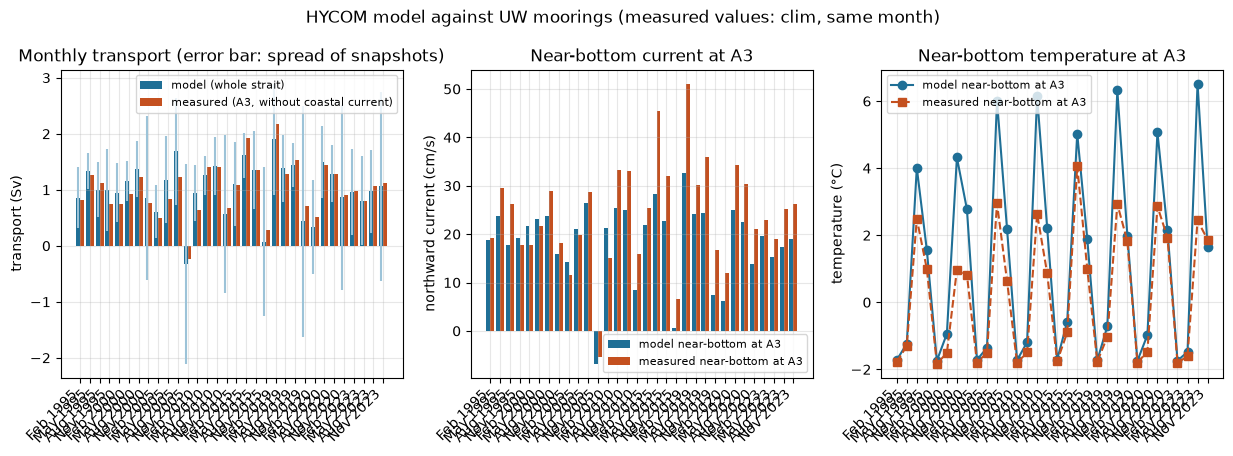

In [7]:
labels = [f"{MONTH_NAMES[m - 1]} {y}" for y, m in zip(cmp["year"], cmp["month"])]
x = np.arange(len(cmp))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(x - 0.2, cmp["transport_sv"], 0.4, yerr=cmp["transport_sd"], color="#1f6f96", ecolor="#9cc3d8", label="model (whole strait)")
axes[0].bar(x + 0.2, cmp["uw_transport_sv"], 0.4, color="#c4501f", label="measured (A3, without coastal current)")
axes[0].set_ylabel("transport (Sv)")
axes[0].set_title("Monthly transport (error bar: spread of snapshots)")
axes[1].bar(x - 0.2, cmp["a3_bottom_v_cms"], 0.4, color="#1f6f96", label="model near-bottom at A3")
axes[1].bar(x + 0.2, cmp["uw_bottom_v_cms"], 0.4, color="#c4501f", label="measured near-bottom at A3")
axes[1].set_ylabel("northward current (cm/s)")
axes[1].set_title("Near-bottom current at A3")
axes[2].plot(x, cmp["a3_bottom_temp_c"], "o-", color="#1f6f96", label="model near-bottom at A3")
axes[2].plot(x, cmp["uw_temp_c"], "s--", color="#c4501f", label="measured near-bottom at A3")
axes[2].set_ylabel("temperature (°C)")
axes[2].set_title("Near-bottom temperature at A3")
for ax in axes:
    ax.set_xticks(x, labels, rotation=45, ha="right")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
kinds = ", ".join(sorted(set(cmp["measured_kind"])))
fig.suptitle(f"HYCOM model against UW moorings (measured values: {kinds})", y=1.03)
fig.savefig(FIG_DIR / "04_model_vs_moorings.png", dpi=150, bbox_inches="tight")
plt.show()

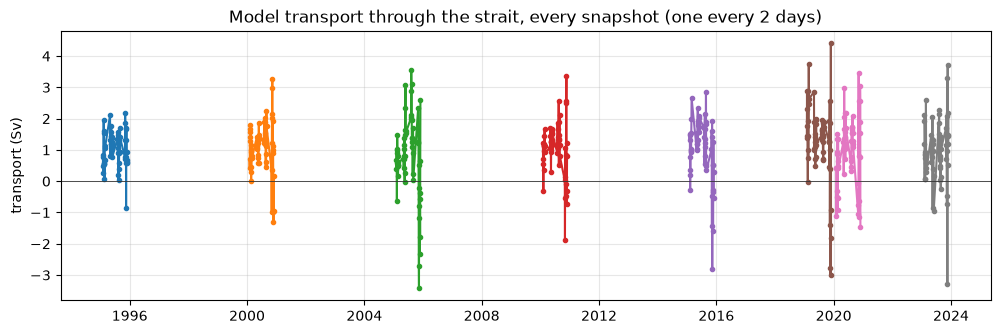

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for y, g in snap.groupby("year"):
    ax.plot(g["date"], g["transport_sv"], "o-", markersize=3, label=str(y))
ax.axhline(0, color="#333333", linewidth=0.6)
ax.set_ylabel("transport (Sv)")
ax.set_title("Model transport through the strait, every snapshot (one every 2 days)")
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "04_snapshot_transport.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 5. Maps of the monthly mean currents

Top row near the surface, bottom row near the seabed, for each downloaded month of `MAP_YEAR`. Colour = speed, arrows = direction.

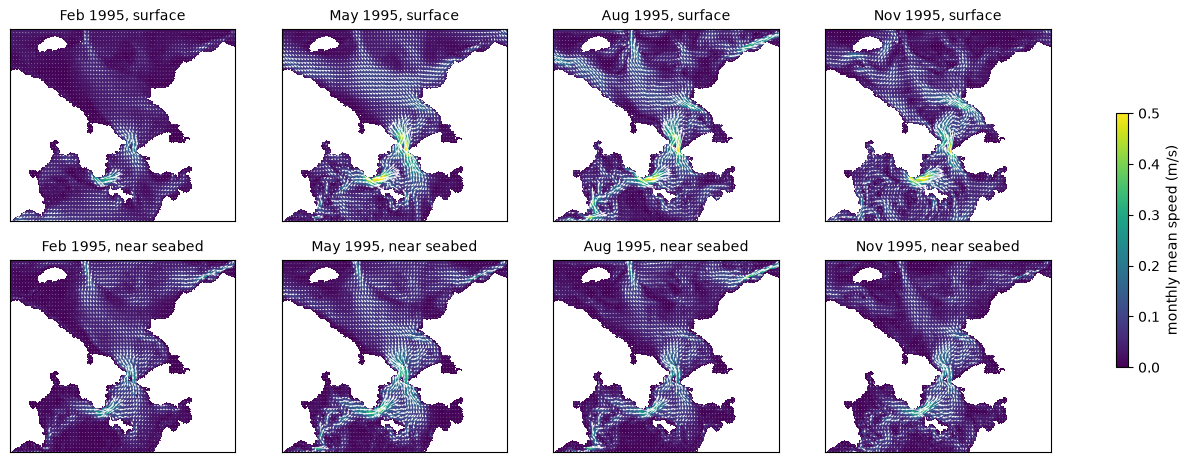

In [9]:
map_year = MAP_YEAR if MAP_YEAR is not None else min(y for y, _ in groups)
months = sorted(m for y, m in groups if y == map_year)
fig, axes = plt.subplots(2, len(months), figsize=(4.2 * len(months), 5.5), squeeze=False)
for j, m in enumerate(months):
    mean = xr.open_dataset(MONTHLY_DIR / f"hycom_mean_{map_year}{m:02d}.nc", engine="h5netcdf").load()
    surf_u = mean["water_u"].isel(depth=0).values
    surf_v = mean["water_v"].isel(depth=0).values
    bot_u = bottom_values(mean["water_u"])
    bot_v = bottom_values(mean["water_v"])
    lon = mean["lon"].values
    lat = mean["lat"].values
    for i, (u, v, name) in enumerate([(surf_u, surf_v, "surface"), (bot_u, bot_v, "near seabed")]):
        ax = axes[i, j]
        sp = np.hypot(u, v)
        pc = ax.pcolormesh(lon, lat, sp, cmap="viridis", vmin=0, vmax=0.5, shading="auto")
        s = MAP_STEP
        ax.quiver(lon[::s], lat[::s], u[::s, ::s], v[::s, ::s], color="white", scale=6, width=0.003)
        ax.set_title(f"{MONTH_NAMES[m - 1]} {map_year}, {name}", fontsize=10)
        ax.set_aspect(1 / np.cos(np.deg2rad(67)))
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(pc, ax=axes, shrink=0.6, label="monthly mean speed (m/s)")
fig.savefig(FIG_DIR / "04_monthly_maps.png", dpi=130, bbox_inches="tight")
plt.show()

___
**END**